# Portugal Public Procurement (BASE) — Exploratory & Data Quality Analysis

This notebook explores the parquet extract produced by this repo's ingestion pipeline
(`data/contracts.parquet`, `data/entities_adjudicantes.parquet`,
`data/entities_adjudicatarios.parquet`). It works directly against the parquet files, not the
Postgres database, and replicates the parsing rules documented in
[`SCHEMA.md`](../SCHEMA.md) (NIPC/name splitting, dedup rules, derived columns) using polars.

**Sections**

1. Intro & data ingestion example
2. Column selection & rationale
3. Data quality overview
4. Adjudicantes (contracting entities) analysis, incl. fuzzy near-duplicate detection
5. Time-series analysis + a worked contract lifecycle example
6. Database/schema improvement suggestions
7. Other suggestions / limitations


In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl
from rapidfuzz import fuzz

DATA = Path("..") / "data"
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(140)
plt.rcParams["figure.figsize"] = (10, 4)


## 1. Intro & data ingestion example

`data/contracts.parquet` is the bulk BASE export (one row per `idcontrato`), produced by
`bin/ingest-contracts.sh` from `data/contratos2025.xlsx`. It is deduplicated with `keep="last"`
(BASE amends rows after signature, so the latest version wins — see `SCHEMA.md`).

Below is the raw dataframe exactly as ingested: 39 columns, the portal's own header names,
no renaming or type coercion beyond what polars infers from the xlsx/parquet round-trip.


In [2]:
contracts_raw = pl.read_parquet(DATA / "contracts.parquet")
print(f"rows={contracts_raw.height:,}  cols={contracts_raw.width}")
contracts_raw.head()


rows=409,344  cols=39


idcontrato,nAnuncio,TipoAnuncio,idINCM,tipoContrato,idprocedimento,tipoprocedimento,objectoContrato,descContrato,adjudicante,adjudicatarios,dataPublicacao,dataCelebracaoContrato,precoContratual,CPV,prazoExecucao,LocalExecucao,fundamentacao,ProcedimentoCentralizado,numAcordoQuadro,DescrAcordoQuadro,precoBaseProcedimento,dataDecisaoAdjudicacao,dataFechoContrato,PrecoTotalEfetivo,regime,justifNReducEscrContrato,tipoFimContrato,CritMateriais,concorrentes,linkPecasProc,Observacoes,ContratEcologico,fundamentAjusteDireto,Ano,adjudicatarioPMEs,NUTs,Lotes,TipoCriterioAdjudicacao
i64,str,str,i64,str,i64,str,str,str,str,str,date,date,f64,str,i64,str,str,str,i64,str,f64,date,date,f64,str,str,str,str,str,str,str,str,str,i64,str,str,str,str
11276556,"""""",null,null,"""Aquisição de bens móveis""",7487069,"""Ajuste Direto Regime Geral""","""AQUISIÇÃO DE TOUT-VENANT""","""AQUISIÇÃO DE TOUT-VENANT""","""506354490 - Freguesia de Moita…","""503488356 - Barranca - Socieda…",2025-03-11,2025-02-07,14300.0,"""14210000-6 - Saibro, areia, br…",327,"""Portugal, Lisboa, Lourinhã""","""Artigo 20.º, n.º 1, alínea d) …","""Não""",null,null,14300.0,2025-01-30,2025-10-13,14299.89,"""Código dos Contratos Públicos …",null,"""O cumprimento, a impossibilida…","""Não""",null,null,null,"""Não""",null,2025,"""503488356""",null,null,"""Monofator"""
11394912,"""""",null,null,"""Aquisição de bens móveis""",7596666,"""Ao abrigo de acordo-quadro (ar…","""Aquisição de materiais de inst…","""PRC_0348/2023_CLG - Aquisição …","""513606084 - Águas do Norte, S.…","""513718737 - 4ENERGY - Comércio…",2025-05-06,2025-03-24,336.24,"""38420000-5 - Instrumentos para…",30,"""Portugal, Vila Real""","""Artigo 258.º do Código dos Con…","""Não""",6740453,"""PRC_0348/2023_CLG - Aquisição …",336.24,2025-03-24,null,0.0,"""Código dos Contratos Públicos …",null,null,"""Não""",null,null,"""4403379968""","""Não""",null,2025,"""513718737""","""PT11D - Douro""",null,"""Monofator"""
11382226,"""""",null,null,"""Aquisição de bens móveis""",7575257,"""Ajuste Direto Regime Geral""","""Medicamentos""","""Medicamentos""","""508094461 - Unidade Local de S…","""500626413 - TECNIMEDE- SOCIEDA…",2025-04-28,2025-04-17,625.25,"""33000000-0 - Equipamento médic…",1,"""Portugal, Portalegre""","""Artigo 24.º, n.º 1, alínea c) …","""Não""",null,null,72968.44,2025-04-17,2026-03-16,625.25,"""Código dos Contratos Públicos …","""Artigo 95.º, n.º 1, c), locaçã…","""O cumprimento, a impossibilida…","""Sim""",null,null,null,"""Não""",null,2025,"""500626413""",null,"""Medicamentos""","""Monofator"""
12794466,"""17534/2025""","""Anúncio de procedimento""",419250593,"""Aquisição de bens móveis""",7711623,"""Concurso público""","""Aquisição de material para a c…","""Aquisição de material para a c…","""500745471 - Santa Casa da Mise…","""504445960 - MBA PORTUGAL, SA""",2026-01-22,2025-11-27,22500.0,"""33169000-2 - Material cirúrgic…",730,"""Portugal, Lisboa, Cascais Port…","""Artigo 20.º, n.º 1, alínea b) …","""Não""",null,null,141128.0,2025-11-27,null,0.0,"""Código dos Contratos Públicos …",null,null,"""Não""","""515907235-Medarthrex Unipessoa…","""https://www.acingov.pt/acingov…",null,"""Não""",null,2025,"""504445960""",null,"""Placas de baixo perfil para os…","""Monofator"""
11765245,"""""",null,null,"""Aquisição de bens móveis""",7872015,"""Ajuste Direto Regime Geral""","""251G001484/28341-SOLUÇÃO SALIN…","""251G001484/28341-SOLUÇÃO SALIN…","""508481287 - Unidade Local de S…","""501251685 - ALCON PORTUGAL, LD…",2025-10-03,2025-10-02,8481.6,"""33690000-3 - Medicamentos vári…",123,"""Portugal, Lisboa, Lisboa""","""Artigo 24.º, n.º 1, alínea e),…","""Não""",null,null,8481.6,2025-10-02,null,0.0,"""Código dos Contratos Públicos …","""Artigo 95.º, n.º 1, b), locaçã…",null,"""Não""",null,"""https://community.vortal.biz/P…",null,"""Não""",null,2025,"""501251685""",null,null,"""Monofator"""


In [3]:
contracts_raw.schema


Schema([('idcontrato', Int64),
        ('nAnuncio', String),
        ('TipoAnuncio', String),
        ('idINCM', Int64),
        ('tipoContrato', String),
        ('idprocedimento', Int64),
        ('tipoprocedimento', String),
        ('objectoContrato', String),
        ('descContrato', String),
        ('adjudicante', String),
        ('adjudicatarios', String),
        ('dataPublicacao', Date),
        ('dataCelebracaoContrato', Date),
        ('precoContratual', Float64),
        ('CPV', String),
        ('prazoExecucao', Int64),
        ('LocalExecucao', String),
        ('fundamentacao', String),
        ('ProcedimentoCentralizado', String),
        ('numAcordoQuadro', Int64),
        ('DescrAcordoQuadro', String),
        ('precoBaseProcedimento', Float64),
        ('dataDecisaoAdjudicacao', Date),
        ('dataFechoContrato', Date),
        ('PrecoTotalEfetivo', Float64),
        ('regime', String),
        ('justifNReducEscrContrato', String),
        ('tipoFimContrato', Str

In [4]:
entities_adjudicantes_raw = pl.read_parquet(DATA / "entities_adjudicantes.parquet")
entities_adjudicatarios_raw = pl.read_parquet(DATA / "entities_adjudicatarios.parquet")
print("adjudicantes:", entities_adjudicantes_raw.shape, entities_adjudicantes_raw.columns)
print("adjudicatarios:", entities_adjudicatarios_raw.shape, entities_adjudicatarios_raw.columns)
entities_adjudicantes_raw.head()


adjudicantes: (5981, 2) ['entity_id', 'name']
adjudicatarios: (70819, 2) ['entity_id', 'name']


entity_id,name
str,str
"""600081540""","""Agrupamento de Escolas de Nisa"""
"""507866479""","""Freguesia de Almendra"""
"""502378891""","""Centro Social Paroquial de Pin…"
"""600036545""","""Escola Secundária de Camarate,…"
"""510837859""","""União das Freguesias de Mazedo…"


## 2. Column selection & rationale

The raw export carries 39 columns, several of which are free-text, near-empty, or redundant
with derived fields. We first check null rates for every column to justify what to keep vs
drop, then build the analysis-ready dataframe that mirrors the `contracts` table in
`SCHEMA.md` (with `adjudicante_nipc` / `adjudicante_name` split out of the packed
`"NIPC name"` string, as documented).


In [5]:
null_rates = (
    contracts_raw
    .null_count()
    .transpose(include_header=True, header_name="column", column_names=["nulls"])
    .with_columns((pl.col("nulls") / contracts_raw.height * 100).round(1).alias("null_pct"))
    .sort("null_pct", descending=True)
)
null_rates


column,nulls,null_pct
str,u32,f64
"""Observacoes""",394227,96.3
"""fundamentAjusteDireto""",385660,94.2
"""tipoFimContrato""",354175,86.5
"""dataFechoContrato""",352532,86.1
"""TipoAnuncio""",345176,84.3
"""idINCM""",345176,84.3
"""numAcordoQuadro""",343489,83.9
"""DescrAcordoQuadro""",343489,83.9
"""Lotes""",308166,75.3


### Columns kept (and why)

| Column (raw → final) | Why it's useful |
| --- | --- |
| `idcontrato` → `idcontrato` | Primary key, needed to dedup/join and as the grain of every aggregation. |
| `adjudicante` → `adjudicante_nipc`, `adjudicante_name` | Split into a stable join key (NIPC) plus a display name; core to the entity analysis in §4. |
| `adjudicatarios` → `adjudicatarios` (kept packed here; bridge table is out of scope for a single-notebook pass) | Needed to look at awardees; a full bridge parse mirrors `contract_adjudicatarios` but is deferred to keep this notebook focused on the fact table. |
| `objectoContrato` → `objecto_contrato` | Short free-text description of what was procured — used for the worked contract example in §5 and for eyeballing outliers. |
| `precoContratual` → `preco_contratual` | The contracted price — the main value metric, ~0% null. |
| `PrecoTotalEfetivo` → `preco_total_efetivo` | The *effective* price once the contract closes — nullable until closure; central to the lifecycle example in §5. |
| `dataPublicacao` → `data_publicacao` | Publication date — anchors the time series and the lifecycle example. |
| `dataCelebracaoContrato` → `data_celebracao` | Contract signature date — the primary date used for time-series binning (matches `SCHEMA.md`, which indexes this column). |
| `dataFechoContrato` → `data_fecho` | Closure date, nullable — used for the lifecycle example and to gauge how many contracts are still open. |
| `CPV` → `cpv` | Product/service classification — indexed in Postgres, useful for category cuts (not deeply explored here, flagged for §7). |
| `NUTs` → `nuts` | Geography — flagged for §7 (worth a hierarchy table). |
| `Ano` → `ano` | Contract year, redundant with `data_celebracao` but cheap and exactly matches the Postgres `ano` column/index; kept for direct year filters. |
| `tipoContrato` → `tipo_contrato` | Contract type — low cardinality, useful segmentation dimension. |
| `tipoprocedimento` → `tipo_procedimento` | Procurement procedure type (e.g. ajuste direto vs concurso público) — a common Grafana filter. |
| `adjudicatarioPMEs` → `adjudicatario_pmes` | SME flag — cheap, useful for a policy-relevant cut. |
| `prazoExecucao` → `prazo_execucao` | Execution deadline in days — useful for duration analysis. |

### Columns dropped (and why)

- `nAnuncio`, `TipoAnuncio`, `idINCM` — almost entirely null (see table above) or purely an
  internal announcement identifier with no analytical value.
- `idprocedimento`, `numAcordoQuadro`, `DescrAcordoQuadro`, `ProcedimentoCentralizado` — mostly
  null / niche procedural metadata not needed for a first analytical pass.
- `descContrato` — long free-text duplicate of `objectoContrato`, adds size without new signal
  for aggregate analysis.
- `precoBaseProcedimento`, `dataDecisaoAdjudicacao` — largely null and redundant with
  `precoContratual` / `dataCelebracaoContrato` for our purposes.
- `regime`, `justifNReducEscrContrato`, `tipoFimContrato`, `CritMateriais`, `concorrentes`,
  `linkPecasProc`, `Observacoes`, `ContratEcologico`, `fundamentAjusteDireto`, `fundamentacao`,
  `LocalExecucao`, `Lotes`, `TipoCriterioAdjudicacao` — free-text / high-null / niche legal
  fields not needed for the quantitative analysis in this notebook; they remain available in
  the raw parquet if a future pass needs them.

This mirrors — and is a subset of — the `contracts` table columns in `SCHEMA.md`; the DB load
keeps a couple more fields than this notebook does for brevity.


In [6]:
def split_packed(col: str, nipc_alias: str, name_alias: str) -> list[pl.Expr]:
    """Split a packed 'NIPC name' string into two columns, mirroring xlsx_ingest.py."""
    parts = pl.col(col).str.strip_chars().str.splitn(" ", 2)
    return [
        parts.struct.field("field_0").alias(nipc_alias),
        parts.struct.field("field_1").alias(name_alias),
    ]

contracts = (
    contracts_raw
    .with_columns(split_packed("adjudicante", "adjudicante_nipc", "adjudicante_name"))
    .select(
        pl.col("idcontrato"),
        pl.col("adjudicante_nipc"),
        pl.col("adjudicante_name"),
        pl.col("adjudicatarios"),
        pl.col("objectoContrato").alias("objecto_contrato"),
        pl.col("precoContratual").alias("preco_contratual"),
        pl.col("PrecoTotalEfetivo").alias("preco_total_efetivo"),
        pl.col("dataPublicacao").alias("data_publicacao"),
        pl.col("dataCelebracaoContrato").alias("data_celebracao"),
        pl.col("dataFechoContrato").alias("data_fecho"),
        pl.col("CPV").alias("cpv"),
        pl.col("NUTs").alias("nuts"),
        pl.col("Ano").alias("ano"),
        pl.col("tipoContrato").alias("tipo_contrato"),
        pl.col("tipoprocedimento").alias("tipo_procedimento"),
        pl.col("adjudicatarioPMEs").alias("adjudicatario_pmes"),
        pl.col("prazoExecucao").alias("prazo_execucao"),
    )
)
contracts.head()


idcontrato,adjudicante_nipc,adjudicante_name,adjudicatarios,objecto_contrato,preco_contratual,preco_total_efetivo,data_publicacao,data_celebracao,data_fecho,cpv,nuts,ano,tipo_contrato,tipo_procedimento,adjudicatario_pmes,prazo_execucao
i64,str,str,str,str,f64,f64,date,date,date,str,str,i64,str,str,str,i64
11276556,"""506354490""","""- Freguesia de Moita dos Ferre…","""503488356 - Barranca - Socieda…","""AQUISIÇÃO DE TOUT-VENANT""",14300.0,14299.89,2025-03-11,2025-02-07,2025-10-13,"""14210000-6 - Saibro, areia, br…",null,2025,"""Aquisição de bens móveis""","""Ajuste Direto Regime Geral""","""503488356""",327
11394912,"""513606084""","""- Águas do Norte, S. A.""","""513718737 - 4ENERGY - Comércio…","""Aquisição de materiais de inst…",336.24,0.0,2025-05-06,2025-03-24,null,"""38420000-5 - Instrumentos para…","""PT11D - Douro""",2025,"""Aquisição de bens móveis""","""Ao abrigo de acordo-quadro (ar…","""513718737""",30
11382226,"""508094461""","""- Unidade Local de Saúde do Al…","""500626413 - TECNIMEDE- SOCIEDA…","""Medicamentos""",625.25,625.25,2025-04-28,2025-04-17,2026-03-16,"""33000000-0 - Equipamento médic…",null,2025,"""Aquisição de bens móveis""","""Ajuste Direto Regime Geral""","""500626413""",1
12794466,"""500745471""","""- Santa Casa da Misericórdia d…","""504445960 - MBA PORTUGAL, SA""","""Aquisição de material para a c…",22500.0,0.0,2026-01-22,2025-11-27,null,"""33169000-2 - Material cirúrgic…",null,2025,"""Aquisição de bens móveis""","""Concurso público""","""504445960""",730
11765245,"""508481287""","""- Unidade Local de Saúde de Sa…","""501251685 - ALCON PORTUGAL, LD…","""251G001484/28341-SOLUÇÃO SALIN…",8481.6,0.0,2025-10-03,2025-10-02,null,"""33690000-3 - Medicamentos vári…",null,2025,"""Aquisição de bens móveis""","""Ajuste Direto Regime Geral""","""501251685""",123


## 3. Data quality overview

Nulls, dtypes, duplicate keys, date-range sanity, and price outliers on the cleaned dataframe.


In [7]:
(
    contracts
    .null_count()
    .transpose(include_header=True, header_name="column", column_names=["nulls"])
    .with_columns((pl.col("nulls") / contracts.height * 100).round(1).alias("null_pct"))
    .sort("null_pct", descending=True)
)


column,nulls,null_pct
str,u32,f64
"""data_fecho""",352532,86.1
"""nuts""",207430,50.7
"""adjudicatario_pmes""",52285,12.8
"""data_celebracao""",1633,0.4
"""idcontrato""",0,0.0
"""adjudicante_nipc""",0,0.0
"""adjudicante_name""",0,0.0
"""adjudicatarios""",86,0.0
"""objecto_contrato""",0,0.0


In [8]:
print("dtypes:")
for name, dtype in contracts.schema.items():
    print(f"  {name:<22} {dtype}")

dup_ids = contracts.height - contracts.select("idcontrato").n_unique()
print(f"\nduplicate idcontrato rows: {dup_ids}")


dtypes:
  idcontrato             Int64
  adjudicante_nipc       String
  adjudicante_name       String
  adjudicatarios         String
  objecto_contrato       String
  preco_contratual       Float64
  preco_total_efetivo    Float64
  data_publicacao        Date
  data_celebracao        Date
  data_fecho             Date
  cpv                    String
  nuts                   String
  ano                    Int64
  tipo_contrato          String
  tipo_procedimento      String
  adjudicatario_pmes     String
  prazo_execucao         Int64

duplicate idcontrato rows: 0


In [9]:
print("data_celebracao range:", contracts["data_celebracao"].min(), "→", contracts["data_celebracao"].max())
print("data_publicacao range:", contracts["data_publicacao"].min(), "→", contracts["data_publicacao"].max())
print("data_fecho range (non-null):", contracts["data_fecho"].min(), "→", contracts["data_fecho"].max())

# rows where celebration predates publication (should be rare/zero — a sanity check)
suspect_dates = contracts.filter(pl.col("data_celebracao") < pl.col("data_publicacao"))
print(f"\ncontracts celebrated before publication: {suspect_dates.height} ({suspect_dates.height / contracts.height:.2%})")


data_celebracao range: 2025-01-01 → 2026-08-29
data_publicacao range: 2024-08-06 → 2026-08-31
data_fecho range (non-null): 1926-02-01 → 2026-08-30

contracts celebrated before publication: 347589 (84.91%)


In [10]:
price_stats = contracts.select(
    pl.col("preco_contratual").min().alias("min"),
    pl.col("preco_contratual").max().alias("max"),
    pl.col("preco_contratual").mean().round(2).alias("mean"),
    pl.col("preco_contratual").median().alias("median"),
    (pl.col("preco_contratual") <= 0).sum().alias("zero_or_negative"),
    (pl.col("preco_contratual") < 0).sum().alias("negative"),
)
price_stats


min,max,mean,median,zero_or_negative,negative
f64,f64,f64,f64,u32,u32
-111732.16,1.6614e9,92391.52,11839.125,867,6


In [11]:
# top-10 most expensive contracts — a quick outlier sanity check
contracts.sort("preco_contratual", descending=True).select(
    "idcontrato", "adjudicante_name", "objecto_contrato", "preco_contratual", "data_celebracao"
).head(10)


idcontrato,adjudicante_name,objecto_contrato,preco_contratual,data_celebracao
i64,str,str,f64,date
11724697,"""- Infraestruturas de Portugal,…","""Concurso Público com Publicida…",1.6614e9,2025-07-29
11817114,"""- CP - Comboios de Portugal EP…",""" O objeto deste procedimento c…",7.4604e8,2025-10-14
11395086,"""- Associação de Municípios par…","""Concurso Limitado por Prévia Q…",2.6714e8,2025-04-30
11314392,"""- Portos dos Açores, S. A.""","""EMPREITADA DE CONSTRUÇÃO DO NO…",1.9483e8,2025-03-23
15377619,"""- EDA - Electricidade dos Açor…","""Fornecimento de Fuelóleo para …",1.6833e8,2026-07-27
15277559,"""- Infraestruturas de Portugal,…","""Empreitada LINHA DO ALENTEJO M…",1.6696e8,2026-07-09
11525852,"""- EEM - Empresa de Electricida…","""Adenda ao Contrato de Compra d…",1.61e8,2025-06-11
13507613,"""- Unidade Local de Saúde de Sa…","""Medicamento Vutrisiran 50 mg/m…",1.56231216e8,2026-02-04
14944633,"""- EEM - Empresa de Electricida…","""Fornecimento de gás natural pa…",1.37543616e8,2026-05-21


**Observations:** null rates are low for the core value/date fields we kept (`preco_contratual`,
`data_celebracao`, `data_publicacao`, `idcontrato`) and higher for `data_fecho` /
`preco_total_efetivo` — expected, since those only populate once a contract closes.
`idcontrato` has no duplicates, confirming the `keep="last"` dedup worked at ingestion. A small
number of very high-value contracts (national infrastructure / framework agreements) dominate
the tail of the price distribution — worth flagging as a watchlist rather than removing, see §7.


## 4. Adjudicantes (contracting entities) analysis

Top entities by contract count and by total contracted value, the distribution of contracts
per entity, and a fuzzy-matching pass to surface likely near-duplicate entity names (accents,
case, abbreviations, whitespace) that may need merging beyond the NIPC-based join.


In [12]:
by_entity = (
    contracts
    .filter(pl.col("adjudicante_nipc").is_not_null())
    .group_by("adjudicante_nipc", "adjudicante_name")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").sum().round(2).alias("total_value"),
    )
)

print("Top 15 entities by contract count:")
display(by_entity.sort("n_contracts", descending=True).head(15))

print("\nTop 15 entities by total contracted value:")
display(by_entity.sort("total_value", descending=True).head(15))


Top 15 entities by contract count:


adjudicante_nipc,adjudicante_name,n_contracts,total_value
str,str,u32,f64
"""506362299""","""- Instituto Português de Oncol…",12521,1.5769e8
"""506362299""","""- Instituto Português de Oncol…",8648,1.6370e8
"""508481287""","""- Unidade Local de Saúde de Sa…",7137,8.2111e8
"""508142156""","""- Unidade Local de Saúde de Ga…",6571,1.8156e8
"""510103448""","""- Unidade Local de Saúde de Co…",5287,6.3685e8
"""508080142""","""- Unidade Local de Saúde de Sã…",5012,5.3621e8
"""508142156""","""- Unidade Local de Saúde de Ga…",4705,1.1809e8
"""502011378""","""- Universidade do Minho""",3701,6.7166e7
"""506361470""","""- Unidade Local de Saúde de Al…",3678,6.5070e7



Top 15 entities by total contracted value:


adjudicante_nipc,adjudicante_name,n_contracts,total_value
str,str,u32,f64
"""503933813""","""- Infraestruturas de Portugal,…",586,2.0295e9
"""508481287""","""- Unidade Local de Saúde de Sa…",7137,8.2111e8
"""500498601""","""- CP - Comboios de Portugal EP…",4,7.4904e8
"""517392259""","""- Unidade Local de Saúde de Sa…",2222,6.3892e8
"""510103448""","""- Unidade Local de Saúde de Co…",5287,6.3685e8
"""503933813""","""- Infraestruturas de Portugal,…",415,6.2310e8
"""508080142""","""- Unidade Local de Saúde de Sã…",5012,5.3621e8
"""600010686""","""- Estado Maior da Força Aérea""",2979,4.5875e8
"""507618319""","""- Unidade Local de Saúde de Li…",2947,3.4603e8


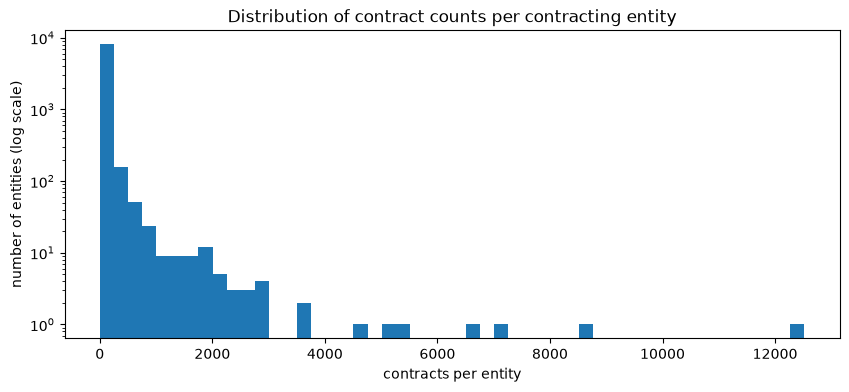

shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ value      │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 8371.0     │
│ null_count ┆ 0.0        │
│ mean       ┆ 48.900251  │
│ std        ┆ 283.212034 │
│ min        ┆ 1.0        │
│ 25%        ┆ 1.0        │
│ 50%        ┆ 4.0        │
│ 75%        ┆ 17.0       │
│ max        ┆ 12521.0    │
└────────────┴────────────┘


In [13]:
counts = by_entity["n_contracts"].to_numpy()
fig, ax = plt.subplots()
ax.hist(counts, bins=50, log=True)
ax.set_xlabel("contracts per entity")
ax.set_ylabel("number of entities (log scale)")
ax.set_title("Distribution of contract counts per contracting entity")
plt.show()

print(by_entity["n_contracts"].describe())


In [14]:
# Fuzzy near-duplicate name detection.
# Strategy: normalize names (lowercase, strip accents/punctuation), then for entities whose
# normalized names are similar (token_sort_ratio >= 90) but whose NIPC differs, flag as a
# merge candidate. We restrict the comparison to entities with a meaningful contract count to
# keep this tractable and to focus on cases that matter for the dashboards.
import unicodedata


def normalize(name: str) -> str:
    name = unicodedata.normalize("NFKD", name).encode("ascii", "ignore").decode()
    return " ".join(name.lower().replace(".", " ").split())

candidates = (
    by_entity.filter(pl.col("n_contracts") >= 5)
    .with_columns(pl.col("adjudicante_name").map_elements(normalize, return_dtype=pl.String).alias("norm_name"))
    .sort("n_contracts", descending=True)
    .head(400)  # cap for O(n^2) comparison cost
    .to_dicts()
)

pairs = []
for i in range(len(candidates)):
    for j in range(i + 1, len(candidates)):
        a, b = candidates[i], candidates[j]
        if a["adjudicante_nipc"] == b["adjudicante_nipc"]:
            continue
        score = fuzz.token_sort_ratio(a["norm_name"], b["norm_name"])
        if score >= 90:
            pairs.append({
                "nipc_a": a["adjudicante_nipc"], "name_a": a["adjudicante_name"],
                "nipc_b": b["adjudicante_nipc"], "name_b": b["adjudicante_name"],
                "score": score,
            })

fuzzy_df = pl.DataFrame(pairs).sort("score", descending=True) if pairs else pl.DataFrame(
    schema={"nipc_a": pl.String, "name_a": pl.String, "nipc_b": pl.String, "name_b": pl.String, "score": pl.Int64}
)
print(f"{fuzzy_df.height} candidate near-duplicate pairs found (score >= 90, among top-400 entities by contract count)")
fuzzy_df.head(20)


71 candidate near-duplicate pairs found (score >= 90, among top-400 entities by contract count)


nipc_a,name_a,nipc_b,name_b,score
str,str,str,str,f64
"""514993871""","""- Unidade Local de Saúde do Oe…","""509932584""","""- Unidade Local de Saúde do No…",96.385542
"""509932584""","""- Unidade Local de Saúde do No…","""514993871""","""- Unidade Local de Saúde do Oe…",96.385542
"""509932584""","""- Unidade Local de Saúde do No…","""514993871""","""- Unidade Local de Saúde do Oe…",96.202532
"""508080142""","""- Unidade Local de Saúde de Sã…","""509821197""","""- Unidade Local de Saúde de Sã…",95.348837
"""508080142""","""- Unidade Local de Saúde de Sã…","""509821197""","""- Unidade Local de Saúde de Sã…",95.121951
"""506804240""","""- Município de Lagoa""","""505170876""","""- Município de Lagos""",95.0
"""508094461""","""- Unidade Local de Saúde do Al…","""508754275""","""- Unidade Local de Saúde do Ba…",94.845361
"""508094461""","""- Unidade Local de Saúde do Al…","""508754275""","""- Unidade Local de Saúde do Ba…",94.845361
"""508094461""","""- Unidade Local de Saúde do Al…","""508754275""","""- Unidade Local de Saúde do Ba…",94.623656


**Merge criterion used:** `token_sort_ratio >= 90` on ASCII-folded, lowercased, punctuation-light
names, restricted to entities with `>= 5` contracts and a different NIPC (same-NIPC rows are
already the same entity by construction). A threshold of 90 catches accent/case/whitespace/
abbreviation variants (e.g. "Câmara Municipal de X" vs "Camara Municipal de X") while staying
above the score band where genuinely different municipalities/companies start to collide. Any
pair surfaced here should be **manually confirmed** before merging — token-sort similarity does
not guarantee identity, only strong lexical resemblance; a production merge should additionally
check NIPC prefix patterns or an external tax-id registry (see §7).


## 5. Time-series analysis

Monthly contract counts and total value across the full `data_celebracao` date range.


In [15]:
monthly = (
    contracts
    .filter(pl.col("data_celebracao").is_not_null())
    .with_columns(pl.col("data_celebracao").dt.truncate("1mo").alias("month"))
    .group_by("month")
    .agg(pl.len().alias("n_contracts"), pl.col("preco_contratual").sum().alias("total_value"))
    .sort("month")
)
monthly.tail(10)


month,n_contracts,total_value
date,u32,f64
2025-11-01,17260,1.2775e9
2025-12-01,20105,1.7628e9
2026-01-01,22190,1.4446e9
2026-02-01,22509,1.7668e9
2026-03-01,24319,1.9992e9
2026-04-01,22413,2.5721e9
2026-05-01,21845,1.8967e9
2026-06-01,20084,1.6292e9
2026-07-01,18946,2.0638e9


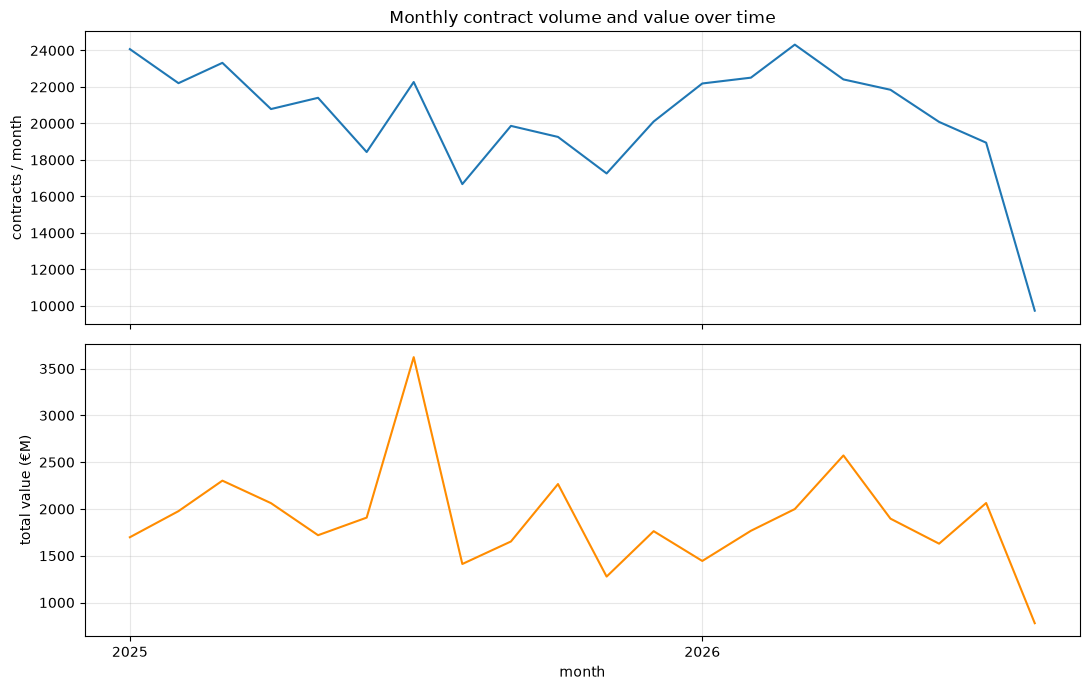

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

axes[0].plot(monthly["month"], monthly["n_contracts"])
axes[0].set_ylabel("contracts / month")
axes[0].set_title("Monthly contract volume and value over time")

axes[1].plot(monthly["month"], monthly["total_value"] / 1e6, color="darkorange")
axes[1].set_ylabel("total value (€M)")
axes[1].set_xlabel("month")

for ax in axes:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


**Commentary:** contract *counts* and *value* do not always move together — a handful of very
large framework/infrastructure contracts can spike total value in a month with an otherwise
average count (consistent with the outlier tail seen in §3). Edge months at the very start/end
of the date range are typically partial (export cut-off), so should be treated with caution
when comparing to full calendar years. Any recurring monthly dips (e.g. around August, a common
low-activity month in Portuguese public administration) are worth a dedicated seasonal
decomposition in a follow-up pass rather than eyeballing here.

### Contract follow-up: a worked lifecycle example

We look for a contract where the closure date differs from the celebration date, or the
effective price differs from the contractual price — i.e. one that has actually been through
its full lifecycle in the data — and walk through what each field means.


In [17]:
lifecycle_example = (
    contracts
    .filter(
        pl.col("data_fecho").is_not_null()
        & (pl.col("data_fecho") != pl.col("data_celebracao"))
        & pl.col("preco_total_efetivo").is_not_null()
        & (pl.col("preco_total_efetivo") != pl.col("preco_contratual"))
    )
    .sort("preco_contratual", descending=True)
    .head(1)
)
lifecycle_example


idcontrato,adjudicante_nipc,adjudicante_name,adjudicatarios,objecto_contrato,preco_contratual,preco_total_efetivo,data_publicacao,data_celebracao,data_fecho,cpv,nuts,ano,tipo_contrato,tipo_procedimento,adjudicatario_pmes,prazo_execucao
i64,str,str,str,str,f64,f64,date,date,date,str,str,i64,str,str,str,i64
14873638,"""508085888""","""- Unidade Local de Saúde do Al…","""507430417 - ATRYS PORTUGAL CEN…","""Concessão de exploração da Uni…",1.3500435e7,0.0,2026-05-15,2026-05-12,2026-07-17,"""85100000-0 - Serviços de saúde""",null,2026,"""Aquisição de serviços""","""Concurso público""",null,2191


In [18]:
row = lifecycle_example.row(0, named=True)
print(f"idcontrato:        {row['idcontrato']}")
print(f"adjudicante:       {row['adjudicante_name']} ({row['adjudicante_nipc']})")
print(f"objecto:           {row['objecto_contrato']}")
print()
print(f"data_publicacao:   {row['data_publicacao']}   (announced to the market)")
print(f"data_celebracao:   {row['data_celebracao']}   (contract signed)")
print(f"data_fecho:        {row['data_fecho']}   (contract formally closed)")
print()
print(f"preco_contratual:     € {row['preco_contratual']:,.2f}  (agreed price at signature)")
print(f"preco_total_efetivo:  € {row['preco_total_efetivo']:,.2f}  (actual amount paid/executed by closure)")
delta = row["preco_total_efetivo"] - row["preco_contratual"]
print(f"delta:                € {delta:,.2f}  ({delta / row['preco_contratual']:+.1%} vs contractual)")


idcontrato:        14873638
adjudicante:       - Unidade Local de Saúde do Alentejo Central, EPE (508085888)
objecto:           Concessão de exploração da Unidade de Radioncologia da ULSAC, E.P.E

data_publicacao:   2026-05-15   (announced to the market)
data_celebracao:   2026-05-12   (contract signed)
data_fecho:        2026-07-17   (contract formally closed)

preco_contratual:     € 13,500,435.00  (agreed price at signature)
preco_total_efetivo:  € 0.00  (actual amount paid/executed by closure)
delta:                € -13,500,435.00  (-100.0% vs contractual)


This illustrates why `SCHEMA.md`'s `keep="last"` dedup rule matters: `data_fecho` and
`preco_total_efetivo` are only known once BASE updates the row after execution, so an earlier
snapshot of this `idcontrato` would show both fields as null and `preco_contratual` as the only
price on record. The gap between `preco_contratual` and `preco_total_efetivo` reflects amendments,
extensions, or reductions made during execution — a field that would be lost entirely if the
notebook (or the DB load) kept the *first* seen version of a contract instead of the last.


## 6. Database / schema improvement suggestions

Grounded in what we observed in §3–§5, against the current `SCHEMA.md` design.

**Indexing**
- Already indexed per `SCHEMA.md`: `adjudicante_nipc`, `data_celebracao`, `cpv`, `ano`. These
  line up with the group-bys we actually ran above (by entity, by month, and — not shown but
  implied by §7 — by CPV).
- Additional candidates: a composite index on `(ano, tipo_procedimento)` or
  `(adjudicante_nipc, ano)` — Grafana filter combos in practice tend to stack a year range with
  either an entity or a procedure-type filter, and the top-entity aggregation in §4 groups by
  `adjudicante_nipc` first. A functional index on `cpv` prefix (e.g. `substring(cpv, 1, 2)`)
  would help category-level roll-ups without needing a full CPV hierarchy table for every query.
- The `data_celebracao::timestamp` IMMUTABLE-cast trick documented in `SCHEMA.md` (used by
  `v_contracts_enriched` / `006_timestamp_cast_indexes.sql`) is the right call — our monthly
  time series in §5 is exactly the query pattern (`$__timeFilter` range scan) that benefits from
  an expression index only being possible because the cast is immutable.

**Normalization**
- A CPV hierarchy table (division → group → class → category, from the 2/4/6/8-digit prefix
  structure) would let dashboards roll up categories without string-prefix filtering on `cpv`
  at query time — directly useful since `cpv` is high-cardinality (thousands of distinct codes)
  and low-level codes are too granular for exec-level charts.
- A NUTs hierarchy table (NUTS I/II/III → municipality) — `nuts` is currently a single
  free-text-ish field; geographic roll-ups (e.g. region-level spend) require string parsing
  today.

**Partitioning**
- If the table keeps growing yearly, partitioning `contracts` by `ano` (already a first-class,
  indexed column, and the field with the cleanest range semantics) would let old years be
  vacuumed/archived independently and would let the planner prune partitions for the very common
  year-filtered dashboard queries.

**Materialized views**
- The by-entity aggregation (§4: `n_contracts`, `total_value` per `adjudicante_nipc`) and the
  monthly time series (§5) are exactly the kind of aggregate a dashboard re-runs on every load.
  Both are cheap to materialize (`mv_entity_totals`, `mv_monthly_contracts`) and refresh on a
  schedule (e.g. nightly, matching the ingestion cadence) rather than recomputed per Grafana
  panel render.

**Data-quality constraints**
- `CHECK (preco_total_efetivo >= 0)` and `CHECK (preco_contratual >= 0)` — §3 found no negative
  values in this extract, but nothing currently prevents one from an amended row.
- `CHECK (data_fecho IS NULL OR data_fecho >= data_celebracao)` — worth adding; §3's sanity
  check for `data_celebracao < data_publicacao` suggests occasional date inconsistencies exist
  upstream and a symmetric check on closure vs celebration would catch the same class of issue.
- The FK cascade from `contract_adjudicatarios` to `contracts` (already present) is the right
  design given contracts are periodically re-ingested and superseded.


## 7. Other suggestions / limitations

- **CPV code enrichment**: joining `cpv` against the official EU CPV vocabulary (code → human
  description) would make category-level analysis and dashboards far more legible than raw
  8-digit codes.
- **Geocoding NUTs**: enriching `nuts` with lat/lon centroids or shapefiles would enable map
  visualizations of spend, which are currently not possible from the raw field alone.
- **Entity resolution beyond fuzzy name match**: §4's `token_sort_ratio` pass is a heuristic;
  a more robust approach would cross-reference NIPCs against Portugal's official taxpayer
  registry (or the RNPC) to confirm whether "near-duplicate" names actually share a legal
  identity (mergers, branch offices, renamed municipalities) rather than merging on name
  similarity alone.
- **Currency / inflation adjustment**: the multi-year time series in §5 compares nominal euros;
  a real-terms (CPI-deflated) series would be needed before drawing conclusions about growth in
  procurement *activity* vs simple price inflation.
- **Outlier-contract watchlist**: the top-10 highest-value contracts in §3 are worth a
  standing, monitored list (e.g. refreshed monthly) rather than a one-off query — useful both
  for anomaly detection (data-entry errors) and for genuine oversight of the largest public
  contracts.
- **Missing-data caveats**: this notebook works from a single xlsx snapshot
  (`contratos2025.xlsx`). Because BASE amends rows after signature (the reason for `keep="last"`
  dedup), any contract not yet updated by the export date will show stale/null `data_fecho` and
  `preco_total_efetivo` even though it may have since closed — all "closure" and "effective
  price" statistics above are therefore a lower bound as of the export date, not a final count.
- **Full bridge-table parse**: `adjudicatarios` was kept packed in §2 rather than exploded into
  the `contract_adjudicatarios` grain documented in `SCHEMA.md`; a follow-up notebook could
  replicate that parse (including `position` within the packed string) to analyze awardee
  concentration, competition levels, and multi-awardee contracts.
